In [1]:
# Install all external packages used in this notebook before running any other cell.
# This CUDA 12.8 PyTorch build matches the NVIDIA GPU setup checked in this project.
%pip install -q torch torchvision --index-url https://download.pytorch.org/whl/cu128
%pip install -q ultralytics albumentations opencv-python matplotlib pandas numpy

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


# YOLOv8 Bangla License Plate Detection Workflow

This single notebook performs the YOLOv8 part of the project:

1. Check the GPU and original dataset.
2. Merge character-level labels into one plate-level label per image.
3. Create clean and degraded plate-detection data.
4. Train, validate, and test YOLOv8.
5. Display the important plots and prediction examples.

Only generated dataset folders and YOLO output folders are written by the notebook. The original `dataset/` folder is not changed.

## 1. Import Libraries and Define Paths

In [1]:
from pathlib import Path
import random
import shutil

import albumentations as A
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from ultralytics import YOLO

ORIGINAL_DATASET = Path("dataset")
PLATE_DATASET = Path("dataset_plate")
PROCESSED_DATASET = Path("dataset_processed")
SPLITS = ["train", "valid", "test"]
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

random.seed(42)
np.random.seed(42)

print("Original dataset:", ORIGINAL_DATASET.resolve())
print("Plate-level dataset output:", PLATE_DATASET.resolve())
print("Processed dataset output:", PROCESSED_DATASET.resolve())

Original dataset: D:\thesis model training\dataset
Plate-level dataset output: D:\thesis model training\dataset_plate
Processed dataset output: D:\thesis model training\dataset_processed


## 2. Check GPU Availability

In [2]:
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    DEVICE = 0
    print("GPU name:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    DEVICE = "cpu"
    print("GPU not detected. Training will run on CPU.")

print("Training device:", DEVICE)

PyTorch version: 2.11.0+cu128
CUDA available: True
GPU name: NVIDIA GeForce RTX 3060
CUDA version: 12.8
Training device: 0


## 3. Verify the Original Dataset

In [3]:
assert ORIGINAL_DATASET.exists(), "The dataset folder was not found."

for split in SPLITS:
    image_dir = ORIGINAL_DATASET / split / "images"
    label_dir = ORIGINAL_DATASET / split / "labels"
    assert image_dir.exists(), f"Missing image directory: {image_dir}"
    assert label_dir.exists(), f"Missing label directory: {label_dir}"

    images = [path for path in image_dir.iterdir() if path.suffix.lower() in IMAGE_EXTENSIONS]
    labels = list(label_dir.glob("*.txt"))
    print(f"{split}: {len(images)} images and {len(labels)} label files")

train: 3544 images and 3544 label files
valid: 383 images and 383 label files
test: 195 images and 195 label files


## 4. Convert Character-Level Labels to Plate-Level Labels

Each character box is changed into corner coordinates. The smallest rectangle covering all characters becomes one `license_plate` box with class ID `0`.

`dataset_plate/` is a generated output folder. The next cell recreates it so that old or incomplete converted files cannot remain in the training data.

In [4]:
if PLATE_DATASET.exists():
    shutil.rmtree(PLATE_DATASET)

converted_counts = {}
empty_counts = {}

for split in SPLITS:
    source_images = ORIGINAL_DATASET / split / "images"
    source_labels = ORIGINAL_DATASET / split / "labels"
    output_images = PLATE_DATASET / split / "images"
    output_labels = PLATE_DATASET / split / "labels"

    output_images.mkdir(parents=True, exist_ok=True)
    output_labels.mkdir(parents=True, exist_ok=True)

    for image_path in source_images.iterdir():
        if image_path.suffix.lower() in IMAGE_EXTENSIONS:
            shutil.copy2(image_path, output_images / image_path.name)

    converted = 0
    empty = 0

    for label_path in source_labels.glob("*.txt"):
        character_boxes = []

        for line in label_path.read_text(encoding="utf-8").splitlines():
            values = line.split()
            if len(values) != 5:
                continue

            _, x_center, y_center, width, height = values
            x_center, y_center, width, height = map(float, (x_center, y_center, width, height))

            x_min = x_center - width / 2
            y_min = y_center - height / 2
            x_max = x_center + width / 2
            y_max = y_center + height / 2
            character_boxes.append((x_min, y_min, x_max, y_max))

        new_label_path = output_labels / label_path.name

        if not character_boxes:
            new_label_path.write_text("", encoding="utf-8")
            empty += 1
            continue

        x_min = max(0.0, min(box[0] for box in character_boxes))
        y_min = max(0.0, min(box[1] for box in character_boxes))
        x_max = min(1.0, max(box[2] for box in character_boxes))
        y_max = min(1.0, max(box[3] for box in character_boxes))

        plate_x_center = (x_min + x_max) / 2
        plate_y_center = (y_min + y_max) / 2
        plate_width = x_max - x_min
        plate_height = y_max - y_min

        output_line = f"0 {plate_x_center:.6f} {plate_y_center:.6f} {plate_width:.6f} {plate_height:.6f}\n"
        new_label_path.write_text(output_line, encoding="utf-8")
        converted += 1

    converted_counts[split] = converted
    empty_counts[split] = empty
    print(f"{split}: {converted} plate labels created, {empty} empty labels kept as background images")

train: 2766 plate labels created, 778 empty labels kept as background images
valid: 261 plate labels created, 122 empty labels kept as background images
test: 134 plate labels created, 61 empty labels kept as background images


## 5. Create the Plate-Level `data.yaml`

In [5]:
plate_yaml = """train: train/images
val: valid/images
test: test/images

nc: 1
names:
  0: license_plate
"""

(PLATE_DATASET / "data.yaml").write_text(plate_yaml, encoding="utf-8")
print((PLATE_DATASET / "data.yaml").read_text(encoding="utf-8"))

train: train/images
val: valid/images
test: test/images

nc: 1
names:
  0: license_plate



## 6. Verify the Converted Labels

A labeled plate image must have exactly one bounding box. Empty label files are allowed as background images when the original annotation file was empty.

In [6]:
for split in SPLITS:
    label_files = list((PLATE_DATASET / split / "labels").glob("*.txt"))
    one_box_files = 0
    empty_files = 0
    incorrect_files = []

    for label_path in label_files:
        lines = [line for line in label_path.read_text(encoding="utf-8").splitlines() if line.strip()]
        if len(lines) == 1:
            one_box_files += 1
        elif len(lines) == 0:
            empty_files += 1
        else:
            incorrect_files.append(label_path.name)

    print(f"{split}: {one_box_files} one-box labels, {empty_files} background labels, {len(incorrect_files)} incorrect labels")
    assert not incorrect_files, f"More than one plate box found in: {incorrect_files[:5]}"

train: 2766 one-box labels, 778 background labels, 0 incorrect labels
valid: 261 one-box labels, 122 background labels, 0 incorrect labels
test: 134 one-box labels, 61 background labels, 0 incorrect labels


## 7. Visualize Character Labels and the New Plate Label

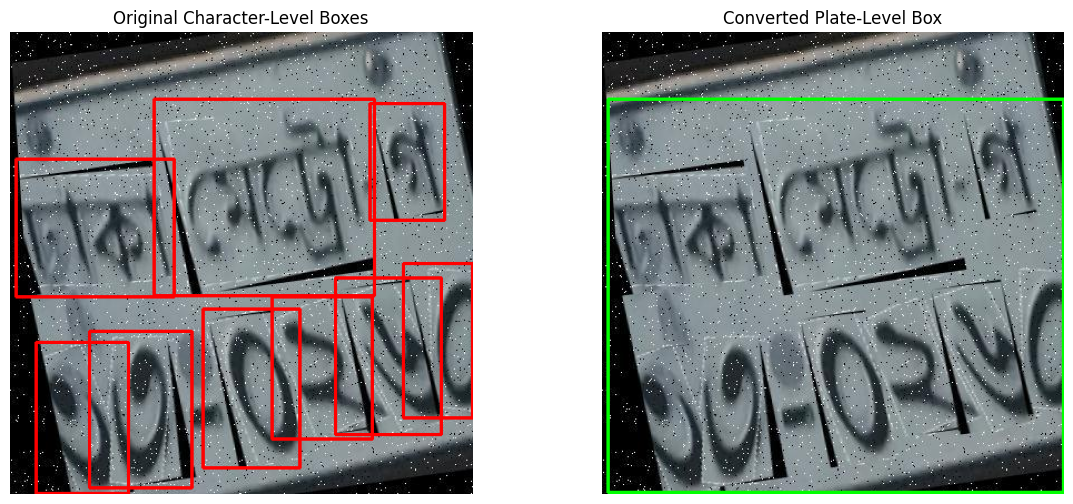

In [7]:
def find_image(image_dir, stem):
    for extension in IMAGE_EXTENSIONS:
        candidate = image_dir / f"{stem}{extension}"
        if candidate.exists():
            return candidate
    return None


def draw_yolo_boxes(image_path, label_path, color):
    image = cv2.cvtColor(cv2.imread(str(image_path)), cv2.COLOR_BGR2RGB)
    height, width = image.shape[:2]

    for line in label_path.read_text(encoding="utf-8").splitlines():
        values = line.split()
        if len(values) != 5:
            continue
        _, x_center, y_center, box_width, box_height = map(float, values)
        x1 = int((x_center - box_width / 2) * width)
        y1 = int((y_center - box_height / 2) * height)
        x2 = int((x_center + box_width / 2) * width)
        y2 = int((y_center + box_height / 2) * height)
        cv2.rectangle(image, (x1, y1), (x2, y2), color, 2)

    return image


sample_label = next(
    path for path in (PLATE_DATASET / "train" / "labels").glob("*.txt")
    if path.read_text(encoding="utf-8").strip()
)
sample_image = find_image(PLATE_DATASET / "train" / "images", sample_label.stem)

original_view = draw_yolo_boxes(
    sample_image,
    ORIGINAL_DATASET / "train" / "labels" / sample_label.name,
    (255, 0, 0)
)
plate_view = draw_yolo_boxes(sample_image, sample_label, (0, 255, 0))

plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
plt.imshow(original_view)
plt.title("Original Character-Level Boxes")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(plate_view)
plt.title("Converted Plate-Level Box")
plt.axis("off")
plt.show()

## 8. Define Motion Blur and Distortion Filters

Albumentations automatically changes the YOLO bounding box after affine or perspective transformations. The processed dataset includes each clean plate-level image and one degraded copy for realistic evaluation on clean and difficult samples.

In [8]:
transform = A.Compose(
    [
        A.MotionBlur(blur_limit=(7, 31), p=0.6),
        A.GaussianBlur(blur_limit=(3, 9), p=0.3),
        A.RandomBrightnessContrast(brightness_limit=0.3, contrast_limit=0.3, p=0.5),
        A.GaussNoise(p=0.3),
        A.ImageCompression(quality_range=(30, 80), p=0.4),
        A.Affine(
            scale=(0.9, 1.1),
            translate_percent=(-0.05, 0.05),
            rotate=(-8, 8),
            shear=(-5, 5),
            p=0.4,
        ),
        A.Perspective(scale=(0.02, 0.06), p=0.3),
    ],
    bbox_params=A.BboxParams(format="yolo", label_fields=["class_labels"], min_visibility=0.3),
)

print("Preprocessing pipeline is ready.")

Preprocessing pipeline is ready.


## 9. Generate the Processed Dataset

`dataset_processed/` is also a generated output folder and is recreated in this cell.

In [9]:
def keep_box_inside_image(box, margin=1e-6):
    x_center, y_center, width, height = box

    x_min = max(margin, x_center - width / 2)
    y_min = max(margin, y_center - height / 2)
    x_max = min(1.0 - margin, x_center + width / 2)
    y_max = min(1.0 - margin, y_center + height / 2)

    if x_max <= x_min or y_max <= y_min:
        return None

    return [
        (x_min + x_max) / 2,
        (y_min + y_max) / 2,
        x_max - x_min,
        y_max - y_min,
    ]


def read_plate_label(label_path):
    boxes = []
    class_labels = []

    if not label_path.exists():
        return boxes, class_labels

    for line in label_path.read_text(encoding="utf-8").splitlines():
        values = line.split()

        if len(values) == 5:
            class_id, x_center, y_center, width, height = values

            box = keep_box_inside_image([
                float(x_center),
                float(y_center),
                float(width),
                float(height)
            ])

            if box is not None:
                boxes.append(box)
                class_labels.append(int(class_id))

    return boxes, class_labels


def write_plate_label(label_path, boxes, class_labels):
    lines = []

    for class_id, box in zip(class_labels, boxes):
        x_center, y_center, width, height = box
        lines.append(
            f"{class_id} {x_center:.6f} {y_center:.6f} {width:.6f} {height:.6f}\n"
        )

    label_path.write_text("".join(lines), encoding="utf-8")


if PROCESSED_DATASET.exists():
    shutil.rmtree(PROCESSED_DATASET)

for split in SPLITS:
    source_images = PLATE_DATASET / split / "images"
    source_labels = PLATE_DATASET / split / "labels"
    output_images = PROCESSED_DATASET / split / "images"
    output_labels = PROCESSED_DATASET / split / "labels"

    output_images.mkdir(parents=True, exist_ok=True)
    output_labels.mkdir(parents=True, exist_ok=True)

    clean_count = 0
    augmented_count = 0

    for image_path in source_images.iterdir():
        if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        source_label = source_labels / f"{image_path.stem}.txt"
        boxes, class_labels = read_plate_label(source_label)

        image = cv2.imread(str(image_path))
        if image is None:
            raise ValueError(f"Could not read image: {image_path}")

        shutil.copy2(image_path, output_images / image_path.name)
        write_plate_label(output_labels / f"{image_path.stem}.txt", boxes, class_labels)
        clean_count += 1

        transformed = transform(
            image=cv2.cvtColor(image, cv2.COLOR_BGR2RGB),
            bboxes=boxes,
            class_labels=class_labels,
        )

        augmented_image_path = output_images / f"{image_path.stem}_aug{image_path.suffix}"
        augmented_image = cv2.cvtColor(transformed["image"], cv2.COLOR_RGB2BGR)
        if not cv2.imwrite(str(augmented_image_path), augmented_image):
            raise ValueError(f"Could not write image: {augmented_image_path}")

        write_plate_label(
            output_labels / f"{image_path.stem}_aug.txt",
            transformed["bboxes"],
            transformed["class_labels"],
        )
        augmented_count += 1

    print(f"{split}: {clean_count} clean images and {augmented_count} augmented images written")

processed_yaml = (PLATE_DATASET / "data.yaml").read_text(encoding="utf-8")
(PROCESSED_DATASET / "data.yaml").write_text(processed_yaml, encoding="utf-8")
print("Processed dataset YAML created at:", PROCESSED_DATASET / "data.yaml")

train: 3544 clean images and 3544 augmented images written
valid: 383 clean images and 383 augmented images written
test: 195 clean images and 195 augmented images written
Processed dataset YAML created at: dataset_processed\data.yaml


## 10. Visualize Clean and Processed Images

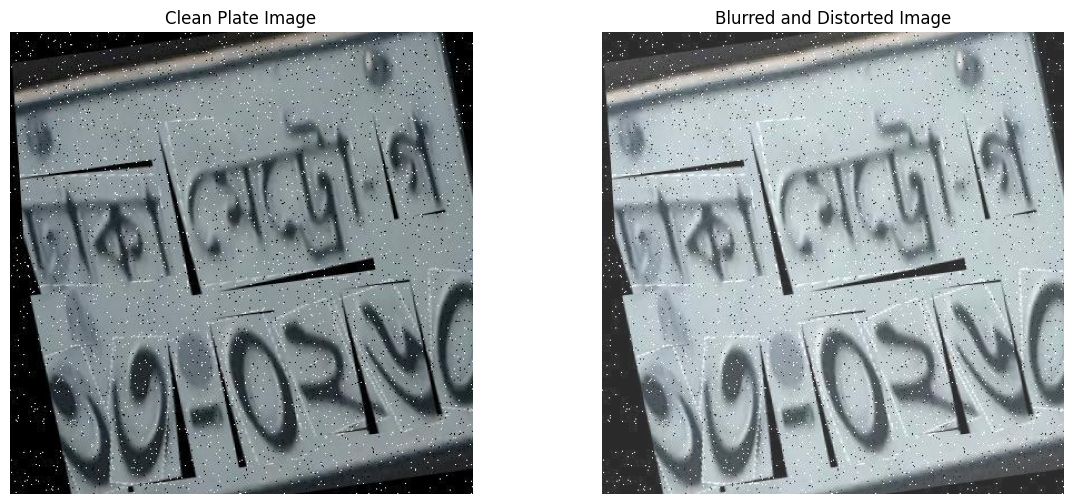

In [10]:
augmented_image = next((PROCESSED_DATASET / "train" / "images").glob("*_aug.*"))
clean_name = augmented_image.name.replace("_aug", "")
clean_image = PROCESSED_DATASET / "train" / "images" / clean_name

clean_view = cv2.cvtColor(cv2.imread(str(clean_image)), cv2.COLOR_BGR2RGB)
augmented_view = cv2.cvtColor(cv2.imread(str(augmented_image)), cv2.COLOR_BGR2RGB)

plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
plt.imshow(clean_view)
plt.title("Clean Plate Image")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(augmented_view)
plt.title("Blurred and Distorted Image")
plt.axis("off")
plt.show()

## 11. Train YOLOv8

`yolov8s.pt` generally provides better accuracy than `yolov8n.pt`. Change `BATCH_SIZE` to `4` if GPU memory is limited.

In [11]:
from pathlib import Path
from ultralytics import YOLO

MODEL_WEIGHTS = "yolov8s.pt"
EPOCHS = 50
IMAGE_SIZE = 640
BATCH_SIZE = 8

RUN_PROJECT = (Path("runs") / "bangla_plate_yolov8").resolve()
RUN_NAME = "plate_motion_blur_distortion_exp"

DATA_YAML = PROCESSED_DATASET / "data.yaml"

model = YOLO(MODEL_WEIGHTS)

training_results = model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    workers=4,
    project=str(RUN_PROJECT),
    name=RUN_NAME,
    plots=True,
    save=True,
    val=True,
    exist_ok=True,
)

RUN_DIR = Path(model.trainer.save_dir)
BEST_MODEL_PATH = Path(model.trainer.best)

print("Training run directory:", RUN_DIR)
print("Best trained model:", BEST_MODEL_PATH)

New https://pypi.org/project/ultralytics/8.4.58 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.54  Python-3.11.4 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3060, 12287MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset_processed\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, n

## 12. Validate and Test the Best Model

In [12]:
best_model = YOLO(str(BEST_MODEL_PATH))

validation_metrics = best_model.val(
    data=str(DATA_YAML),
    split="val",
    imgsz=IMAGE_SIZE,
    device=DEVICE,
)

test_metrics = best_model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=IMAGE_SIZE,
    device=DEVICE,
)

prediction_results = best_model.predict(
    source=str(PROCESSED_DATASET / "test" / "images"),
    imgsz=IMAGE_SIZE,
    conf=0.25,
    device=DEVICE,
    save=True,
    project=str(RUN_DIR.parent),
    name="final_test_predictions",
    exist_ok=True,
)

prediction_dir = RUN_DIR.parent / "final_test_predictions"
print("Predictions saved at:", prediction_dir)

Ultralytics 8.4.54  Python-3.11.4 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3060, 12287MiB)
Model summary (fused): 73 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access  (ping: 0.20.1 ms, read: 1.71.1 MB/s, size: 34.1 KB)
val: Scanning D:\thesis model training\dataset_processed\valid\labels.cache... 766 images, 244 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 766/766  0.0s
WARNING NMS time limit 2.050s exceeded
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 48/48 2.0it/s 24.3s0.3ss
                   all        766        522      0.797      0.722      0.787      0.509
Speed: 4.2ms preprocess, 10.1ms inference, 0.0ms loss, 1.8ms postprocess per image
Results saved to D:\thesis model training\runs\detect\val-3
Ultralytics 8.4.54  Python-3.11.4 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3060, 12287MiB)
val: Fast image access  (ping: 23.813.9 ms, read: 2.11.0 MB/s, size: 72.6 KB)
val: Scanning D:\

## 13. Plot Training Loss, Precision, and Recall

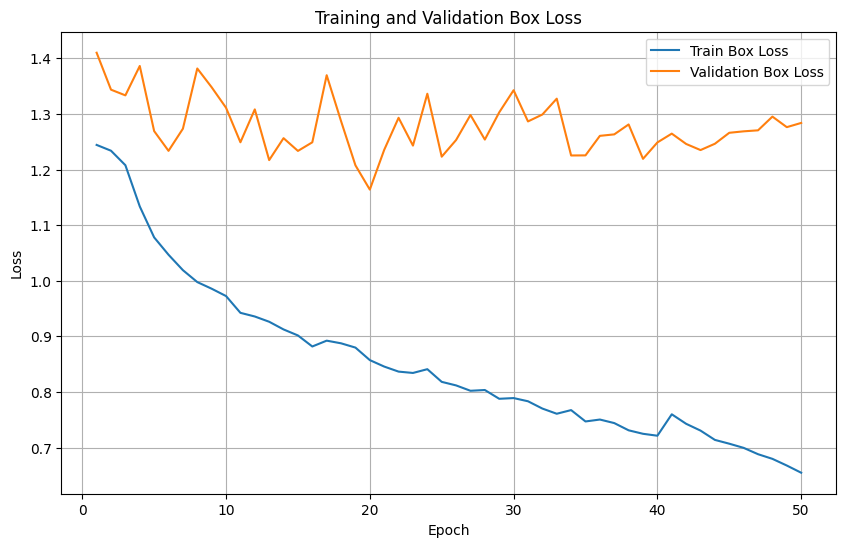

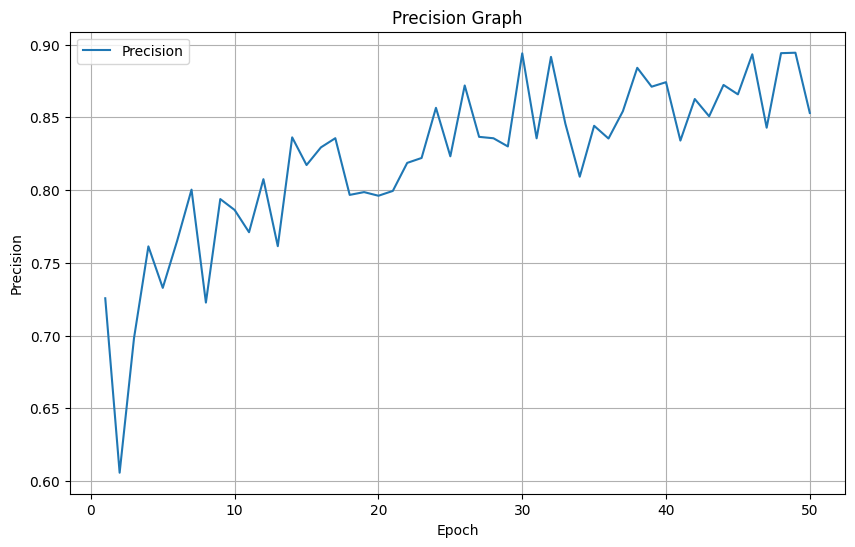

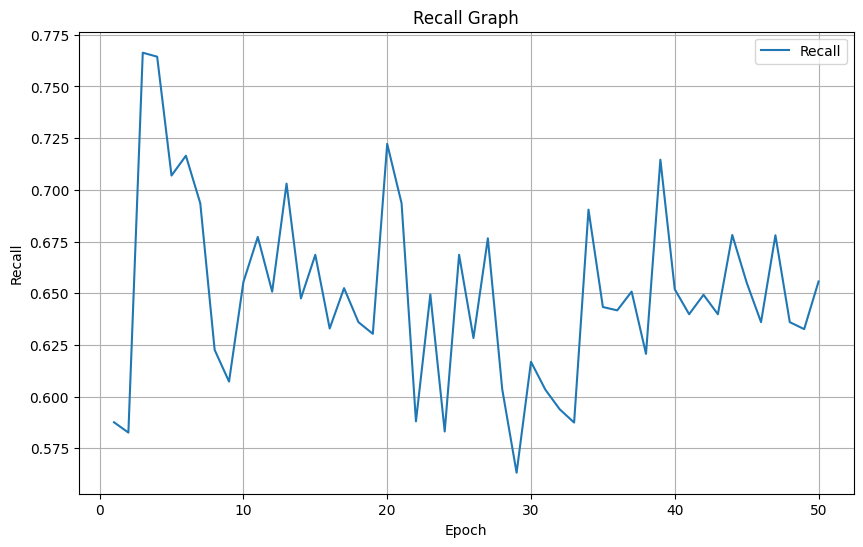

In [13]:
results_csv = RUN_DIR / "results.csv"
results_table = pd.read_csv(results_csv)
results_table.columns = results_table.columns.str.strip()

plt.figure(figsize=(10, 6))
plt.plot(results_table["epoch"], results_table["train/box_loss"], label="Train Box Loss")
plt.plot(results_table["epoch"], results_table["val/box_loss"], label="Validation Box Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Box Loss")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(results_table["epoch"], results_table["metrics/precision(B)"], label="Precision")
plt.xlabel("Epoch")
plt.ylabel("Precision")
plt.title("Precision Graph")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(results_table["epoch"], results_table["metrics/recall(B)"], label="Recall")
plt.xlabel("Epoch")
plt.ylabel("Recall")
plt.title("Recall Graph")
plt.legend()
plt.grid(True)
plt.show()

## 14. Show YOLOv8 Saved Thesis Outputs

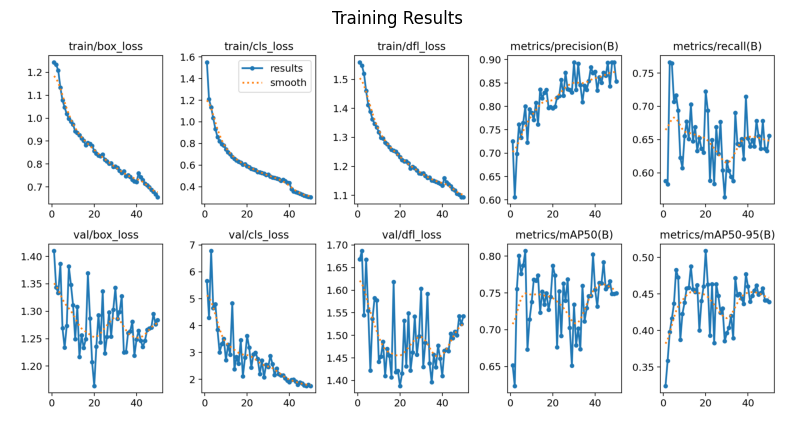

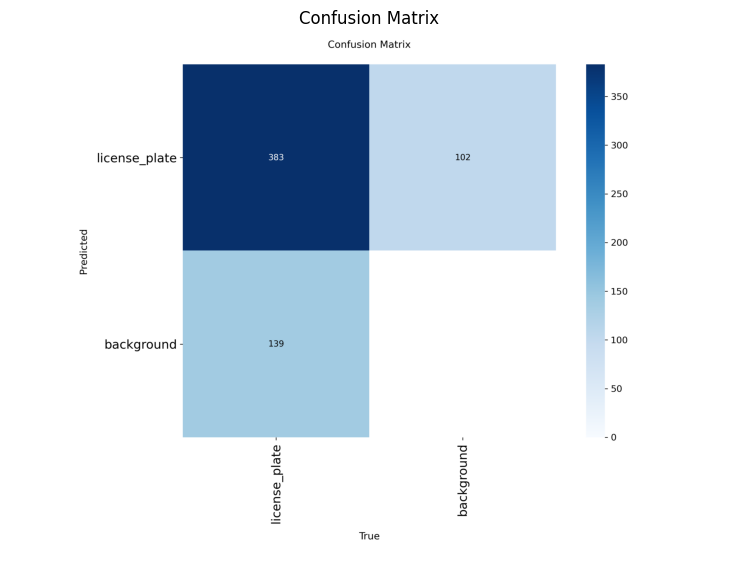

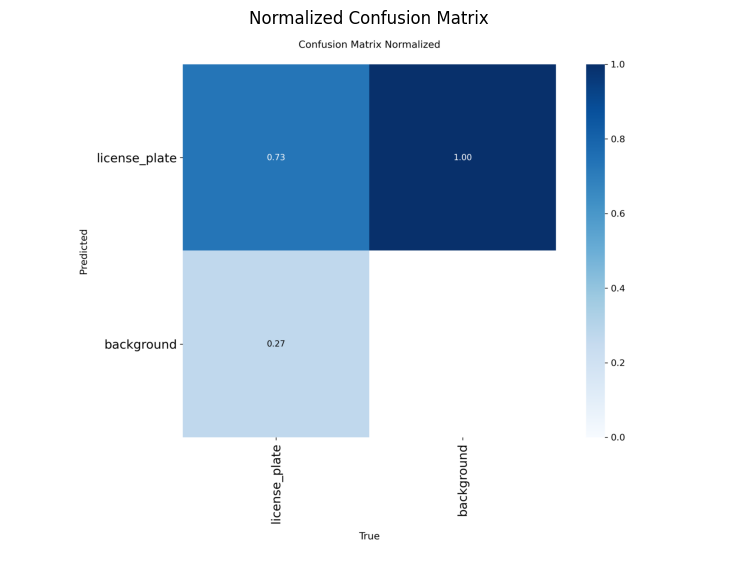

File not found: D:\thesis model training\runs\bangla_plate_yolov8\plate_motion_blur_distortion_exp\PR_curve.png
File not found: D:\thesis model training\runs\bangla_plate_yolov8\plate_motion_blur_distortion_exp\F1_curve.png


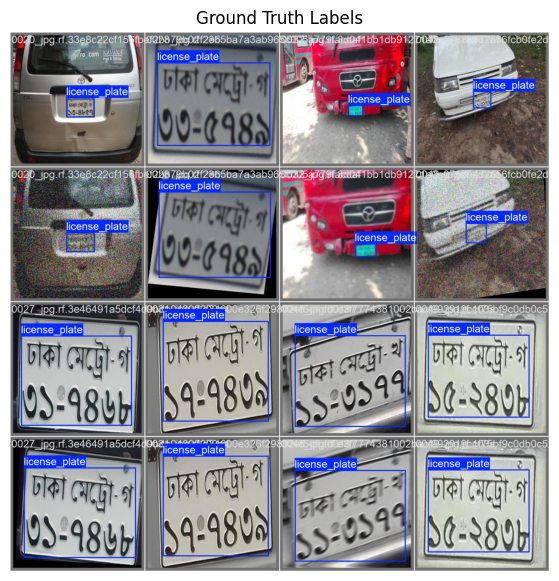

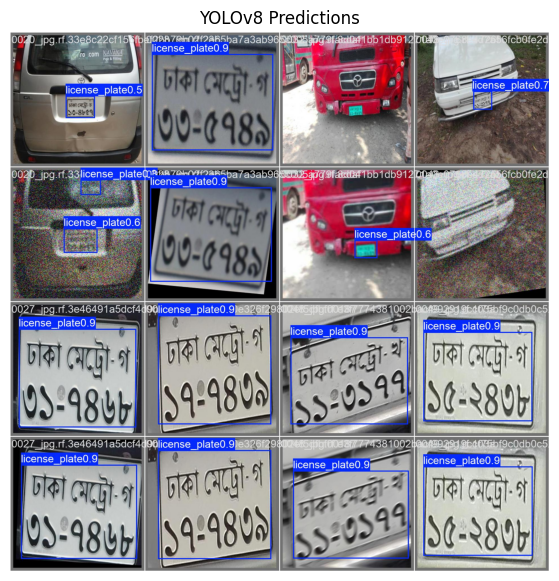

In [14]:
def show_saved_image(image_path, title):
    if not image_path.exists():
        print("File not found:", image_path)
        return
    image = cv2.cvtColor(cv2.imread(str(image_path)), cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(10, 7))
    plt.imshow(image)
    plt.title(title)
    plt.axis("off")
    plt.show()


show_saved_image(RUN_DIR / "results.png", "Training Results")
show_saved_image(RUN_DIR / "confusion_matrix.png", "Confusion Matrix")
show_saved_image(RUN_DIR / "confusion_matrix_normalized.png", "Normalized Confusion Matrix")
show_saved_image(RUN_DIR / "PR_curve.png", "Precision-Recall Curve")
show_saved_image(RUN_DIR / "F1_curve.png", "F1-Confidence Curve")
show_saved_image(RUN_DIR / "val_batch0_labels.jpg", "Ground Truth Labels")
show_saved_image(RUN_DIR / "val_batch0_pred.jpg", "YOLOv8 Predictions")

## 15. Generate and Show Final Test Predictions


image 1/390 d:\thesis model training\dataset_processed\test\images\0002_jpg.rf.3bf1dc611f927cbc8b8f119b7667d962.jpg: 640x640 1 license_plate, 145.4ms
image 2/390 d:\thesis model training\dataset_processed\test\images\0002_jpg.rf.3bf1dc611f927cbc8b8f119b7667d962_aug.jpg: 640x640 1 license_plate, 66.6ms
image 3/390 d:\thesis model training\dataset_processed\test\images\0004_jpg.rf.496eb8b2ca5aac7bd580574dbf849442.jpg: 640x640 (no detections), 9.6ms
image 4/390 d:\thesis model training\dataset_processed\test\images\0004_jpg.rf.496eb8b2ca5aac7bd580574dbf849442_aug.jpg: 640x640 1 license_plate, 10.5ms
image 5/390 d:\thesis model training\dataset_processed\test\images\0011_jpg.rf.0727f5ac59e6eb69ad6dcb4f8d237a3d.jpg: 640x640 1 license_plate, 13.0ms
image 6/390 d:\thesis model training\dataset_processed\test\images\0011_jpg.rf.0727f5ac59e6eb69ad6dcb4f8d237a3d_aug.jpg: 640x640 1 license_plate, 9.7ms
image 7/390 d:\thesis model training\dataset_processed\test\images\0015_jpg.rf.46b65e4777ad668

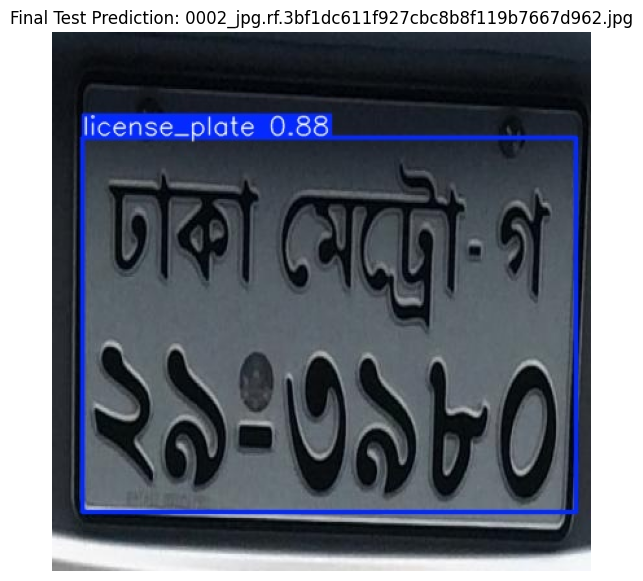

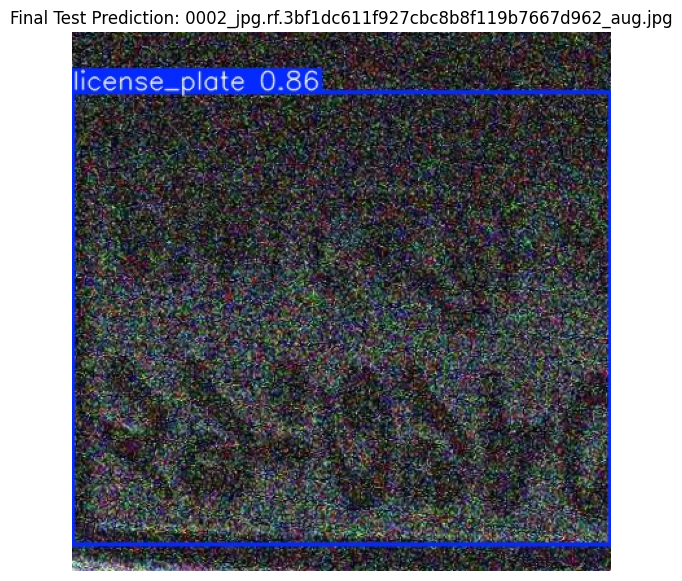

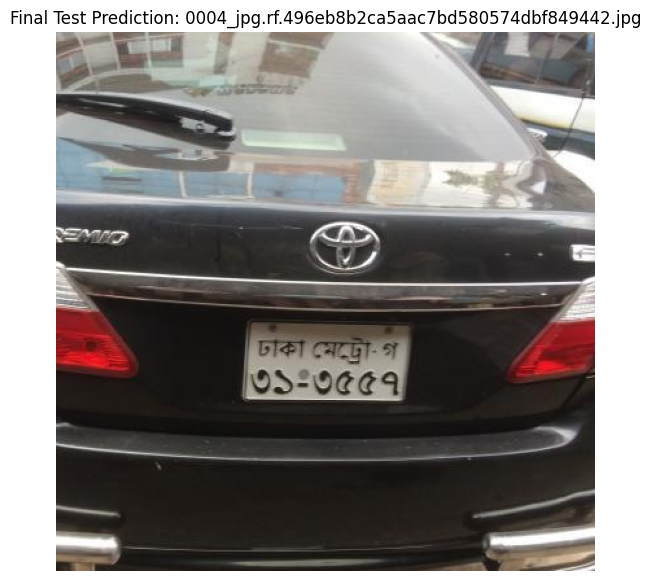

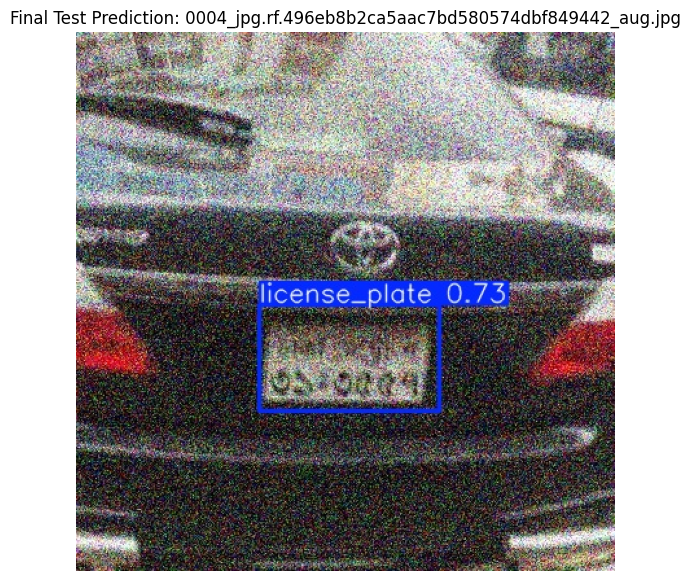

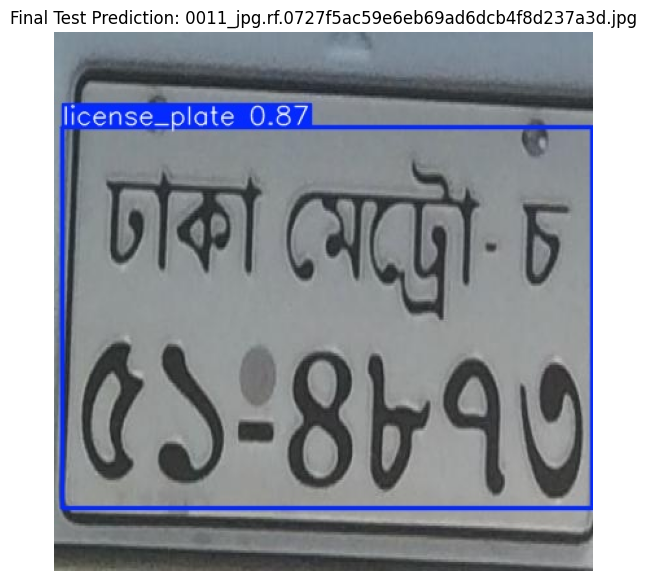

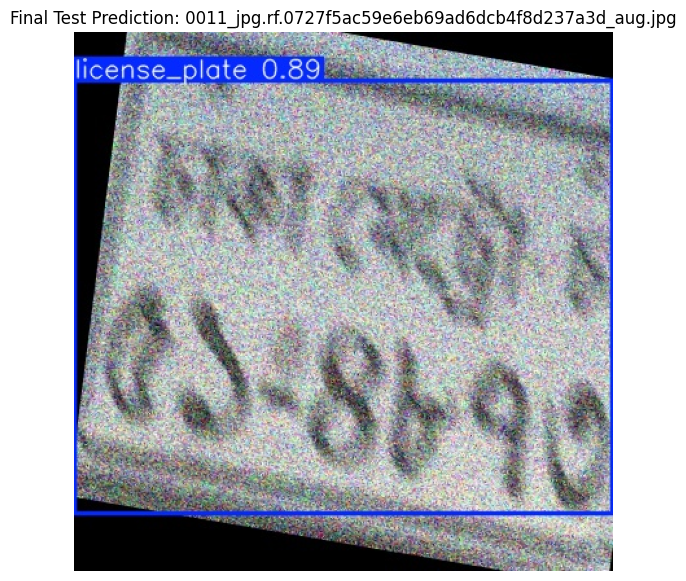

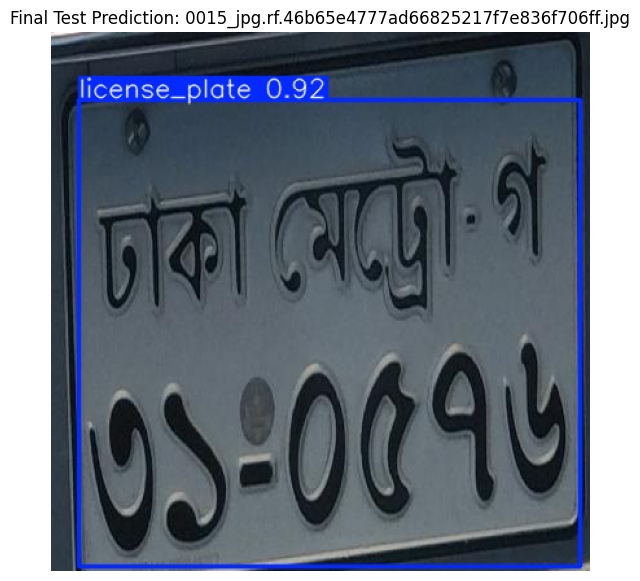

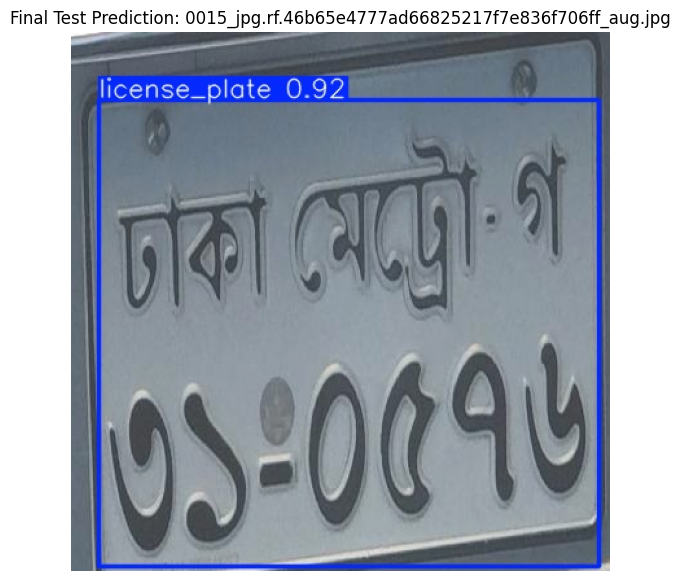

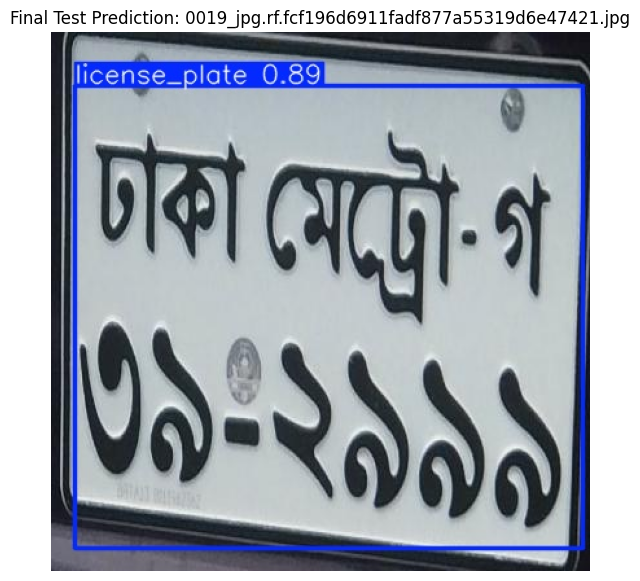

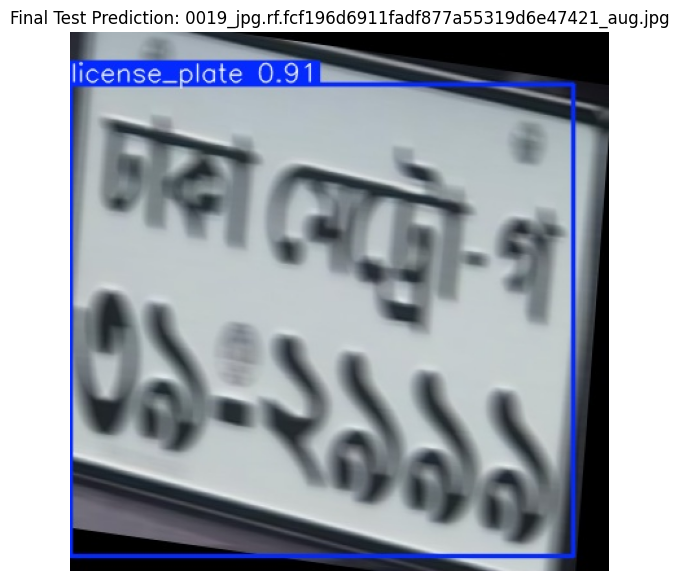

Final model saved at: D:\thesis model training\runs\bangla_plate_yolov8\plate_motion_blur_distortion_exp\weights\best.pt


In [15]:
prediction_results = best_model.predict(
    source=str(PROCESSED_DATASET / "test" / "images"),
    imgsz=IMAGE_SIZE,
    conf=0.25,
    device=DEVICE,
    save=True,
    project=RUN_PROJECT,
    name="final_test_predictions",
    exist_ok=True,
)

prediction_dir = Path(RUN_PROJECT) / "final_test_predictions"
prediction_images = [
    path for path in prediction_dir.iterdir()
    if path.suffix.lower() in IMAGE_EXTENSIONS
][:10]

for image_path in prediction_images:
    show_saved_image(image_path, f"Final Test Prediction: {image_path.name}")

print("Final model saved at:", BEST_MODEL_PATH)